## Section 2 - Configuration

All paths, classes and hyperparameters in one place. Provisional values are marked as such.

In [1]:
# 2.1 Run once per environment, then leave it commented
# %pip install -q shapely pandas scikit-learn einops scipy opencv-python

In [2]:
# 2.2 Imports 
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from PIL import Image
from einops import rearrange
from scipy import ndimage
from shapely.geometry import Polygon
from sklearn.decomposition import PCA
import transformers
from transformers import AutoModel, CLIPImageProcessor


In [3]:
# 2.3 Paths
# One single project root. In this way the notebook can be executed everywhere
# Separated outputs per notebook
# Folder existence check
PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEOS_DIR = PROJECT_ROOT / "data" / "raw_videos"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_perception"
PROTOTYPES_PATH = OUTPUT_DIR / "prototypes.npz"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "VIDEOS_DIR": VIDEOS_DIR}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] VIDEOS_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos


In [4]:
# 2.4 Official class list. Annotations are checked against it in Section 4,
# and its order fixes the color of each class in every plot.
CLASS_NAMES = [
    "background", "body", "base", "hat", "eyes", "ear",
    "nose", "moustache", "mouth", "arm_1", "arm_2", "hand",
]
BACKGROUND_LABEL = "background"
HAND_LABEL = "hand"  # annotated so hand patches do not pollute other prototypes; never reported as a piece

_cmap = plt.get_cmap("tab20")
# Hand-picked palette: 11 clearly distinct colors for the classes, light grey for background.
# Similar pieces (arm_1 / arm_2, nose / mouth / ear) get colors far apart on purpose.
CLASS_COLORS_HEX = {
    "background": "#d9d9d9",   # light grey
    "body":       "#4363d8",   # blue
    "base":       "#f58231",   # orange
    "hat":        "#911eb4",   # purple
    "eyes":       "#3cb44b",   # green
    "ear":        "#f032e6",   # magenta
    "nose":       "#e6194b",   # red
    "moustache":  "#9a6324",   # brown
    "mouth":      "#ffe119",   # yellow
    "arm_1":      "#42d4f4",   # cyan
    "arm_2":      "#808000",   # olive
    "hand":       "#469990",   # teal
}
assert set(CLASS_COLORS_HEX) == set(CLASS_NAMES), "Every class needs exactly one color"
CLASS_COLORS = {name: mcolors.to_rgb(hex_color) for name, hex_color in CLASS_COLORS_HEX.items()}

In [5]:
# 2.5 Hyperparameters
# For each the section in which is used

# --- Feature extraction (Section 3) ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- PCA visualization (Section 3, visualization only) ---
PCA_N_COMPONENTS = 3
PCA_BORDER_EXCLUDE = 2          # patches excluded on each side when fitting the PCA
PCA_CLIP_PERCENTILES = (1, 99)

# --- Patch labelling (Section 5) ---
MIN_LABEL_COVERAGE = 0.5        # a patch gets a piece label if that piece covers at least this fraction of it

# --- Border-artifact check (Sections 6.6 and 10) ---
EXTREME_NORM_FACTOR = 5         # a patch is "extreme" if its norm exceeds 5x the median norm of its frame

# --- Support-set gallery (Section 7, visualization only) ---
GALLERY_MARGIN = 1              # extra patches shown around each crop
GALLERY_DIM_FACTOR = 0.35       # brightness of pixels outside the patches used for the prototype

# --- Classification (Section 9) ---
CONFIDENCE_MARGIN = 0.03        # provisional: justified in the dedicated margin study

# --- Video pipeline (Section 11) ---
MOTION_THRESHOLD = 1.0          # mean absolute gray-level difference (0-255) between consecutive frames
STABLE_FRAMES_NEEDED = 5        # consecutive still frames before running C-RADIO (~167 ms at 30 fps)
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the video overlay

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


Thesis "Experimental setup"

## Section 3 - Model and feature extraction

C-RADIOv4-SO400M is used as frozen feature extractor: no training or fine-tuning.

In [7]:
# 3.1 Loading the model
# Model in inference mode on GPU. The patch size (16x16) is read by the model
t0 = time.time()
image_processor = CLIPImageProcessor.from_pretrained(MODEL_DIR)
model = AutoModel.from_pretrained(MODEL_DIR, trust_remote_code=True)
model.eval().to(DEVICE)
torch.cuda.synchronize()
print(f"Model loaded in {time.time() - t0:.2f}s")

PATCH_SIZE = getattr(model, "patch_size", 16)
print(f"Patch size: {PATCH_SIZE}x{PATCH_SIZE} pixels")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded in 5.55s
Patch size: 16x16 pixels


In [8]:
# 3.2 Preprocessor
# The preprocessor rescales the pixels in [0,1] and does not normalize (do_normalize: false). 
print(image_processor)

CLIPImageProcessor {
  "crop_size": {
    "height": 512,
    "width": 512
  },
  "do_center_crop": false,
  "do_convert_rgb": true,
  "do_normalize": false,
  "do_rescale": true,
  "do_resize": false,
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "CLIPImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 512
  }
}



In [9]:
# 3.3 Input normalization is internal to the model (input conditioner):
# per-channel (x - mean) / std with the CLIP constants, applied after the preprocessor's [0, 1] rescaling.
conditioner = model.radio_model.input_conditioner
for name, value in conditioner.named_buffers():
    print(f"{name}: {value.flatten().tolist()}")

norm_mean: [0.48145467042922974, 0.45782750844955444, 0.40821072459220886]
norm_std: [0.2686295509338379, 0.2613025903701782, 0.27577710151672363]


3.4 Feature extraction. Input: the RGB frame (1024x1024), pixel values rescaled in [0,1] by the preprocessor, bfloat16. Input normalization is done inside the model (input conditioner, 3.3): per-channel (x − mean) / std with the CLIP constants (mean 0.481, 0.458, 0.408; std 0.269, 0.261, 0.276). The preprocessor does not normalize (do_normalize: false, 3.2) to avoid normalizing twice. Output: one 1152-dimensional vector per 16x16 patch, i.e. a 64x64 grid of 4096 vectors. The global summary vector is not used: the whole method works at patch level.

In [10]:
# 3.4 Feature Extraction
def extract_patch_features(pil_image):
    """
    Run C-RADIOv4 on one RGB image and return one feature vector per patch.

    Returns
    -------
    features : np.ndarray of shape (h_patches, w_patches, D), float32
    resized_size : (width, height) the image was resized to before entering the model
    """
    height, width = model.get_nearest_supported_resolution(height=pil_image.height, width=pil_image.width)
    resized = pil_image.resize((width, height), Image.Resampling.LANCZOS)

    inputs = image_processor(images=resized, return_tensors="pt", do_resize=False)
    pixel_values = inputs.pixel_values.to(device=DEVICE, dtype=DTYPE)

    with torch.no_grad(), torch.autocast(DEVICE, dtype=DTYPE):
        summary, patch_tokens = model(pixel_values)  # the global summary vector is not used

    h_patches, w_patches = height // PATCH_SIZE, width // PATCH_SIZE
    features = rearrange(patch_tokens, "1 (h w) d -> h w d", h=h_patches, w=w_patches)
    return features.float().cpu().numpy(), (width, height)


EXAMPLE_FRAME = FRAMES_DIR / "3_disassembled_ordered_f0001.jpg"

example_image = Image.open(EXAMPLE_FRAME).convert("RGB")
example_features, example_resized_size = extract_patch_features(example_image)
h_patches, w_patches, feat_dim = example_features.shape

print(f"Original size  : {example_image.width}x{example_image.height}")
print(f"Model input    : {example_resized_size[0]}x{example_resized_size[1]}")
print(f"Patch grid     : {w_patches}x{h_patches} = {w_patches * h_patches} patches")
print(f"Feature dim D  : {feat_dim}")

Original size  : 1024x1024
Model input    : 1024x1024
Patch grid     : 64x64 = 4096 patches
Feature dim D  : 1152


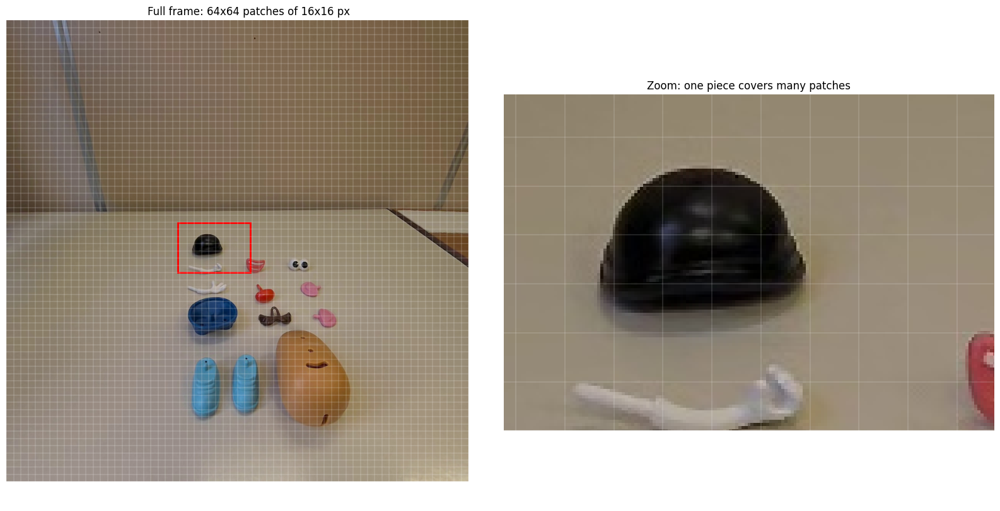

In [11]:
# 3.5 Patch grid
# What is a patch from a visual point of view. 
# A piece covers a lot of patches
# The edge patches are mixed
ZOOM_BOX = (380, 450, 540, 560)  # (x0, y0, x1, y1) in model-input pixels: adjust to frame one piece

example_resized = example_image.resize(example_resized_size, Image.Resampling.LANCZOS)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax in axes:
    ax.imshow(example_resized)
    for x in range(0, example_resized_size[0] + 1, PATCH_SIZE):
        ax.axvline(x, color="white", linewidth=0.3, alpha=0.6)
    for y in range(0, example_resized_size[1] + 1, PATCH_SIZE):
        ax.axhline(y, color="white", linewidth=0.3, alpha=0.6)
    ax.axis("off")

x0, y0, x1, y1 = ZOOM_BOX
axes[0].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"Full frame: {w_patches}x{h_patches} patches of {PATCH_SIZE}x{PATCH_SIZE} px")
axes[1].set_xlim(x0, x1)
axes[1].set_ylim(y1, y0)  # image y axis points down
axes[1].set_title("Zoom: one piece covers many patches")
plt.tight_layout()
plt.show()

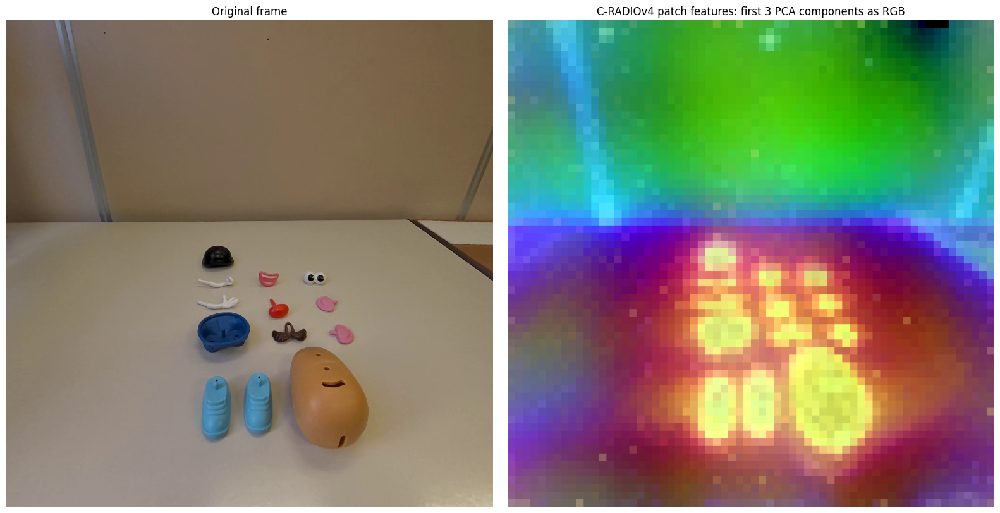

Variance explained by each component: [0.165 0.087 0.068] (total 31.9%)


In [12]:
# 3.6 Feature PCA
# Projection of the 1152 dimension on 3 to visualize them as RGB
def pca_to_rgb(features, border=PCA_BORDER_EXCLUDE, clip=PCA_CLIP_PERCENTILES, seed=RANDOM_SEED):
    """Project patch features onto their first 3 principal components and map them to RGB.
    Visualization only: the classifier always uses the full D-dimensional features."""
    h, w, d = features.shape
    fit_on = features[border:h - border, border:w - border].reshape(-1, d)
    pca = PCA(n_components=PCA_N_COMPONENTS, random_state=seed).fit(fit_on)
    projected = pca.transform(features.reshape(-1, d))
    low, high = np.percentile(projected, clip, axis=0)
    rgb = np.clip((projected - low) / (high - low + 1e-8), 0, 1)
    return rgb.reshape(h, w, 3), pca.explained_variance_ratio_


pca_rgb, explained = pca_to_rgb(example_features)
pca_rgb_full = cv2.resize(pca_rgb, example_image.size, interpolation=cv2.INTER_NEAREST)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(example_image)
axes[0].set_title("Original frame")
axes[1].imshow(pca_rgb_full)
axes[1].set_title("C-RADIOv4 patch features: first 3 PCA components as RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Variance explained by each component: {explained.round(3)} (total {explained.sum():.1%})")

Observation 3.6: The first three components separate background (wall, table) from objects, but they explain only 31.9% of the variance. Differences between pieces live in the remaining dimensions, which is why classification uses all 1152 dimensions and not the PCA. The dark patch in the top-right corner is a border artifact: this is why border patches are excluded from the PCA fit.
(confirmed by the norm analysis in 6.6)

References Section 3: 

C-RADIOv4 tech report Model and extraction 3.1-3.4; 

Dosovitskiy et al. 2021, An Image is Worth 16x16 Words (ViT) Patch Grid 3.5;

Oquab et al. 2023, DINOv2 + C-RADIOv4 tech report for PCA as standard visualization 3.6;



## Section 4 - Dataset

Stratified selection of reference frames based on explicit variable factors: assembled, partially assembled, disassembled, seen from above, base from two poses, hands.

4.1 Reference frames. The reference frames are the support set (Snell et al. 2017): the few annotated examples the prototypes are built from. Each frame declares which classes it provides (use_labels). Annotated polygons with other labels are ignored, not counted as background. The old shoe/pants labels are always ignored: base is only annotated when feet and pants are mounted together

In [13]:
# 4.1 Reference frames
PIECE_LABELS = set(CLASS_NAMES) - {BACKGROUND_LABEL, HAND_LABEL}
LEGACY_LABELS = {"shoe", "pants"}  # old annotations, superseded by "base": always ignored

# Each reference frame declares which classes it contributes to the prototypes.
# Annotated polygons with any other label are ignored (neither used nor counted as background).
REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
]


def sequence_of(frame_name):
    """Frames are named <sequence>_f<index>: the sequence is everything before the last '_f'."""
    return frame_name.rsplit("_f", 1)[0]


for ref in REFERENCE_FRAMES:
    ref["image_path"] = FRAMES_DIR / f"{ref['frame']}.jpg"
    ref["json_path"] = FRAMES_DIR / f"{ref['frame']}.json"
    ref["sequence"] = sequence_of(ref["frame"])

In [14]:
# 4.2 Annotation check
# Automatic verification of file, dimensions and labels
# The table documents where each prototype comes from.
rows = []
for ref in REFERENCE_FRAMES:
    assert ref["image_path"].exists(), f"Missing image: {ref['image_path']}"
    assert ref["json_path"].exists(), f"Missing annotation: {ref['json_path']}"

    with open(ref["json_path"]) as f:
        annotation = json.load(f)
    with Image.open(ref["image_path"]) as img:
        assert (img.width, img.height) == (annotation["imageWidth"], annotation["imageHeight"]), \
            f"Image/annotation size mismatch in {ref['frame']}"

    annotated = {shape["label"] for shape in annotation["shapes"]}
    unknown = annotated - set(CLASS_NAMES) - LEGACY_LABELS
    assert not unknown, f"Unknown labels in {ref['frame']}: {unknown}"

    ref["used_labels"] = annotated & ref["use_labels"]
    rows.append({
        "frame": ref["frame"],
        "sequence": ref["sequence"],
        "role": ref["role"],
        "used": ", ".join(sorted(ref["used_labels"])),
        "ignored": ", ".join(sorted(annotated - ref["use_labels"])) or "-",
    })

display(pd.DataFrame(rows))

print("\nFrames contributing to each class:")
for label in sorted(PIECE_LABELS | {HAND_LABEL}):
    frames = [ref["frame"] for ref in REFERENCE_FRAMES if label in ref["used_labels"]]
    print(f"  {label:<10} {len(frames)} frame(s): {', '.join(frames) if frames else '— NONE'}")

,frame,sequence,role,used,ignored
0,5_assembled_f0002,5_assembled,assembled,"arm_1, arm_2, base, body, ear, eyes, hat, mous...",-
1,caos_f0149,caos,partially assembled,"arm_1, base, body, ear, eyes, hat, moustache, ...",-
2,3_disassembled_ordered_f0001,3_disassembled_ordered,disassembled,"arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
3,2_disassembled_caos_f0016,2_disassembled_caos,"disassembled, top-down view","arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
4,Take_3_1_Base_f0099,Take_3_1_Base,"base only, upright",base,-
5,Take_3_1_Base_f0131,Take_3_1_Base,"base only, lying",base,-
6,caos_f0211,caos,hands,hand,"body, ear, eyes, hat, moustache, nose, pants, ..."



Frames contributing to each class:
  arm_1      4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  arm_2      3 frame(s): 5_assembled_f0002, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  base       4 frame(s): 5_assembled_f0002, caos_f0149, Take_3_1_Base_f0099, Take_3_1_Base_f0131
  body       4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  ear        4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  eyes       4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  hand       1 frame(s): caos_f0211
  hat        4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  moustache  4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  mouth      4 frame(s): 5_assembled_f0002, caos_f0149, 3_d

Observation 4.2: Every piece class is covered by 4 reference frames, except arm_2 (3 frames: only one arm is visible in caos_f0149) and hand (1 frame).

In [15]:
# 4.3 Sequence split against temporal data leakage.
# Sequences reserved for testing: no frame from these videos may contribute to the prototypes.
TEST_SEQUENCES = {"assembly_1", "assembly_2", "1_disassembled_controlled_caos"}

reference_sequences = {ref["sequence"] for ref in REFERENCE_FRAMES}
leaked = reference_sequences & TEST_SEQUENCES
assert not leaked, f"Data leakage: {leaked} used both for prototypes and for testing"

print("Prototype sequences:", sorted(reference_sequences))
print("Test sequences     :", sorted(TEST_SEQUENCES))

# Test frames: stratified by assembly stage, from test sequences only (never used for prototypes)
TEST_FRAMES = [
    {"frame": "assembly_1_f0000", "stage": "all pieces loose"},
    {"frame": "assembly_1_f0008", "stage": "base only"},
    {"frame": "assembly_1_f0016", "stage": "body on base"},
    {"frame": "assembly_1_f0026", "stage": "face in progress (mouth)"},
    {"frame": "assembly_1_f0038", "stage": "face in progress (nose, moustache)"},
    {"frame": "assembly_1_f0054", "stage": "eyes and ears mounted"},
    {"frame": "assembly_1_f0065", "stage": "arms mounted"},
    {"frame": "assembly_1_f0073", "stage": "complete with hat"},
    {"frame": "assembly_1_f0020", "stage": "hands (gloves) on the body"},
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view"},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view"},
]
for test in TEST_FRAMES:
    test["image_path"] = FRAMES_DIR / f"{test['frame']}.jpg"
    test["sequence"] = sequence_of(test["frame"])
    assert test["image_path"].exists(), f"Missing test frame: {test['image_path']}"
    assert test["sequence"] in TEST_SEQUENCES, f"{test['frame']} is not from a test sequence"

print(f"{len(TEST_FRAMES)} test frames from sequences: {sorted({t['sequence'] for t in TEST_FRAMES})}")

Prototype sequences: ['2_disassembled_caos', '3_disassembled_ordered', '5_assembled', 'Take_3_1_Base', 'caos']
Test sequences     : ['1_disassembled_controlled_caos', 'assembly_1', 'assembly_2']
17 test frames from sequences: ['1_disassembled_controlled_caos', 'assembly_1', 'assembly_2']


References Section 4: 

Snell et al. - 2017 - Prototypical Networks for Few-shot Learning Reference Frames 4.1 

Sener et al. 2022 (Assembly101), Sez. 4.6; Schoonbeek et al. 2024 (IndustReal), Sez. 4.4 Sequence Split 4.3 



## Section 5 - From polygons to patch labels

Annotations are at pixel level, the model is at patch level: a conversion rule is needed.

5.1 Rasterization. 
The labelme polygons are converted into a pixel map: each pixel holds the id of its class, 0 if it is not inside any polygon (background), or IGNORE_ID if its polygon belongs to a class the frame must not provide (e.g. old shoe/pants). Ignored pixels are neither piece nor background, so they cannot contaminate the background prototype. Mounted pieces overlap: the eyes polygon lies inside the body polygon, so the eye pixels belong to both. Polygons are painted from the largest to the smallest, like layers of paint: the body first, the eyes on top. The eye pixels therefore get the label eyes, whatever the order of annotation in labelme. The map is then resized to the model input resolution (nearest neighbour, so class ids are not mixed), aligned with the C-RADIO patch grid.

In [16]:
# 5.1 Rasterization: From polygons to pixel map
IGNORE_ID = len(CLASS_NAMES)  # extra id for pixels of polygons that must be ignored in this frame
PATCH_LABEL_NAMES = CLASS_NAMES + ["(ignored)"]


def rasterize_annotation(ref, target_size):
    """
    Turn the labelme polygons of one reference frame into a pixel map at model-input resolution.
    Each pixel holds a class index (0 = background, i.e. not annotated) or IGNORE_ID.
    Polygons are drawn from largest to smallest, so a piece mounted on top of another
    (e.g. eyes on the body) always wins, regardless of the order in the JSON file.
    """
    with open(ref["json_path"]) as f:
        annotation = json.load(f)

    pixel_map = np.zeros((annotation["imageHeight"], annotation["imageWidth"]), dtype=np.uint8)
    shapes = sorted(annotation["shapes"], key=lambda s: Polygon(s["points"]).area, reverse=True)

    for shape in shapes:
        assert shape.get("shape_type", "polygon") == "polygon", f"Non-polygon shape in {ref['frame']}"
        label = shape["label"]
        value = CLASS_NAMES.index(label) if label in ref["use_labels"] else IGNORE_ID
        points = np.round(np.array(shape["points"])).astype(np.int32)
        cv2.fillPoly(pixel_map, [points], int(value))

    return cv2.resize(pixel_map, target_size, interpolation=cv2.INTER_NEAREST)

5.2 Patch labelling. Each 16x16 patch gets one label from the pixel map. A patch gets a piece label if that piece holds the absolute majority of its pixels (coverage ≥ MIN_LABEL_COVERAGE = 0.5). It is background only if it is 100% unannotated. All other patches (mixed boundary patches, ignored polygons) are ignored, like the void label in PASCAL VOC and Cityscapes. A simpler alternative, the center-pixel rule, uses one pixel out of 256 to decide the label of the whole patch (compared in 5.3 and 6.8).

In [17]:
# 5.2 From pixel map to patch labels
def patch_label_grid(pixel_map, min_coverage=MIN_LABEL_COVERAGE):
    """
    Assign one label per patch from the pixel map.
    - piece label : the most frequent class is a piece and covers >= min_coverage of the patch
    - background  : the patch is 100% unannotated
    - ignored     : everything else (mixed boundary patches, ignored polygons)
    Returns the label grid (h_patches, w_patches) and the per-class pixel fractions.
    """
    H, W = pixel_map.shape
    h_p, w_p = H // PATCH_SIZE, W // PATCH_SIZE
    blocks = (pixel_map[:h_p * PATCH_SIZE, :w_p * PATCH_SIZE]
              .reshape(h_p, PATCH_SIZE, w_p, PATCH_SIZE)
              .transpose(0, 2, 1, 3)
              .reshape(h_p, w_p, -1))                                   # (h_p, w_p, 256 pixels)

    fractions = np.stack([(blocks == i).mean(axis=-1) for i in range(IGNORE_ID + 1)], axis=-1)
    majority = fractions.argmax(axis=-1)
    majority_fraction = fractions.max(axis=-1)

    labels = np.full((h_p, w_p), IGNORE_ID, dtype=np.int32)
    labels[fractions[..., 0] == 1.0] = 0                                # pure background
    is_piece = (majority != 0) & (majority != IGNORE_ID) & (majority_fraction >= min_coverage)
    labels[is_piece] = majority[is_piece]
    return labels, fractions

In [18]:
# 5.3 Applying to frames and threshold analysis 
for ref in REFERENCE_FRAMES:
    with Image.open(ref["image_path"]) as img:
        height, width = model.get_nearest_supported_resolution(height=img.height, width=img.width)
    ref["resized_size"] = (width, height)
    ref["pixel_map"] = rasterize_annotation(ref, ref["resized_size"])
    ref["patch_labels"], ref["patch_fractions"] = patch_label_grid(ref["pixel_map"])


def count_per_class(label_grids):
    ids, counts = np.unique(np.concatenate([g.ravel() for g in label_grids]), return_counts=True)
    return dict(zip(ids, counts))


center = PATCH_SIZE // 2
rules = {"center pixel": count_per_class(
    [ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE] for ref in REFERENCE_FRAMES])}
for threshold in (0.25, 0.5, 0.75):
    rules[f"coverage >= {threshold}"] = count_per_class(
        [patch_label_grid(ref["pixel_map"], threshold)[0] for ref in REFERENCE_FRAMES])

patch_counts = pd.DataFrame(rules).reindex(range(len(PATCH_LABEL_NAMES))).fillna(0).astype(int)
patch_counts.index = PATCH_LABEL_NAMES
display(patch_counts)

,center pixel,coverage >= 0.25,coverage >= 0.5,coverage >= 0.75
background,27209,26744,26744,26744
body,234,229,226,199
base,186,185,184,163
hat,37,38,38,25
eyes,25,24,24,14
ear,40,39,39,25
nose,26,23,23,13
moustache,28,27,27,17
mouth,21,21,20,10
arm_1,33,29,28,14


Observation 5.3: With the center-pixel rule, 465 mixed boundary patches ended up in the background prototype. Thresholds 0.25 and 0.5 give almost identical counts, because the majority rule already requires most of the patch to be the piece. At 0.75, small classes lose 42–55% of their patches (arm_2 11 → 5, mouth 20 → 10). We therefore use 0.5: every patch is at least half the piece, without emptying the small classes.

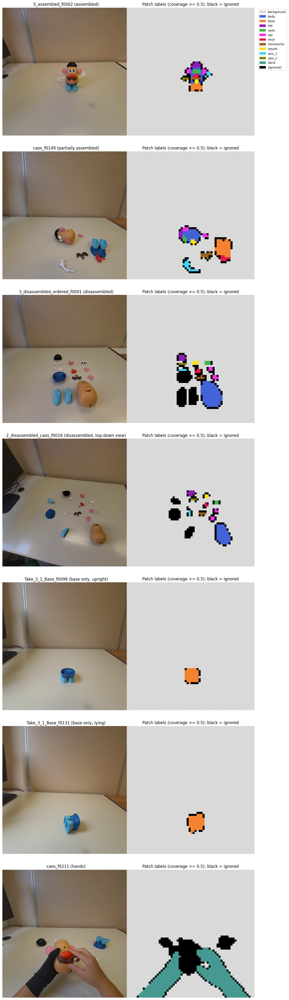

In [19]:
# 5.4 Visual Check
# on all reference frames: small pieces prevail over the body, mixed patches form a thin frame.
def label_grid_to_rgb(label_grid):
    palette = np.array([CLASS_COLORS[name] for name in CLASS_NAMES] + [(0.0, 0.0, 0.0)])  # ignored = black
    return palette[label_grid]

legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES] + \
         [mpatches.Patch(color="black", label="(ignored)")]

fig, axes = plt.subplots(len(REFERENCE_FRAMES), 2, figsize=(12, 6 * len(REFERENCE_FRAMES)))
for row, ref in zip(axes, REFERENCE_FRAMES):
    image = Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"])
    label_rgb = cv2.resize(label_grid_to_rgb(ref["patch_labels"]), ref["resized_size"],
                           interpolation=cv2.INTER_NEAREST)
    row[0].imshow(image)
    row[0].set_title(f"{ref['frame']} ({ref['role']})")
    row[1].imshow(label_rgb)
    row[1].set_title(f"Patch labels (coverage >= {MIN_LABEL_COVERAGE}); black = ignored")
    for ax in row:
        ax.axis("off")

axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Observation 5.4: Every visible piece is either labelled or ignored (black): no piece leaked into the background. Mounted pieces prevail over the body. Limitation: thin pieces such as the arms produce mostly mixed patches, so they contribute fewer examples than their size suggests.

References Section 5:

PASCAL VOC (Everingham et al. 2010, The PASCAL Visual Object Classes (VOC) Challenge, IJCV) marks as "void" a thin band around the edge of each object, because the boundary pixels are ambiguous.

Cityscapes (Cordts et al. 2016, The Cityscapes Dataset for Semantic Urban Scene Understanding, CVPR) has "void" classes excluded from both training and evaluation.

Tools used: labelme: Kentaro Wada, labelme: Image Polygonal Annotation with Python, repository GitHub (wkentaro/labelme)
Russell et al. 2008, LabelMe: a database and web-based tool for image annotation, International Journal of Computer Vision

## Section 6 - Prototypes construction and save

One prototype per class: the normalized mean of its patch features (6.2). Prototypes are saved with their metadata for reuse (6.4).

In [20]:
# 6.1 Feature extraction for all reference frames
for ref in REFERENCE_FRAMES:
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], resized_size = extract_patch_features(image)
    assert resized_size == ref["resized_size"], f"Resolution mismatch in {ref['frame']}"
    assert ref["features"].shape[:2] == ref["patch_labels"].shape, f"Grid mismatch in {ref['frame']}"

print(f"Features extracted for {len(REFERENCE_FRAMES)} reference frames, "
      f"grid {ref['features'].shape[1]}x{ref['features'].shape[0]}, D = {ref['features'].shape[2]}")

Features extracted for 7 reference frames, grid 64x64, D = 1152


6.2 Prototype construction. Each patch vector is L2-normalized (only its direction is kept, since classification uses cosine similarity), all normalized patches of a class are pooled across the reference frames with the same weight (patch-weighted), and their mean is normalized again. This is the maximum-likelihood mean direction of a von Mises-Fisher distribution (Banerjee et al. 2005), the same procedure as weight imprinting (Qi et al. 2018). Ignored patches never enter any prototype.

In [21]:
# 6.2 Prototype construction: normalized mean, patch-weighted
def l2_normalize(x, eps=1e-8):
    """Scale vectors to unit length along the last axis (only their direction is kept)."""
    return x / (np.linalg.norm(x, axis=-1, keepdims=True) + eps)


def build_prototypes(reference_frames):
    """
    One prototype per class, computed as follows:
      1. every patch feature is L2-normalized (brought to length 1);
      2. all normalized patches of the class are pooled across ALL reference frames,
         each patch with the same weight (patch-weighted mean);
      3. their mean is L2-normalized again.
    This is the maximum-likelihood mean direction of a von Mises-Fisher distribution,
    the natural prototype when classification uses cosine similarity.
    Ignored patches (IGNORE_ID) never enter any prototype.
    """
    vectors_per_class = {name: [] for name in CLASS_NAMES}
    for ref in reference_frames:
        features = l2_normalize(ref["features"])
        for class_id, name in enumerate(CLASS_NAMES):
            mask = ref["patch_labels"] == class_id
            if mask.any():
                vectors_per_class[name].append(features[mask])

    prototypes, patch_counts = {}, {}
    for name, chunks in vectors_per_class.items():
        if not chunks:
            continue
        pooled = np.concatenate(chunks)
        prototypes[name] = l2_normalize(pooled.mean(axis=0))
        patch_counts[name] = len(pooled)
    return prototypes, patch_counts


prototypes, prototype_patch_counts = build_prototypes(REFERENCE_FRAMES)

missing = [name for name in CLASS_NAMES if name not in prototypes]
assert not missing, f"No patches for classes: {missing}"
print(f"{len(prototypes)} prototypes built, each a unit vector of dimension {len(next(iter(prototypes.values())))}")

12 prototypes built, each a unit vector of dimension 1152


In [22]:
# 6.3 Patches per class and per reference frame
count_table = pd.DataFrame(
    {ref["frame"]: [int((ref["patch_labels"] == i).sum()) for i in range(len(CLASS_NAMES))]
     for ref in REFERENCE_FRAMES},
    index=CLASS_NAMES,
)
count_table["total"] = count_table.sum(axis=1)
display(count_table)

,5_assembled_f0002,caos_f0149,3_disassembled_ordered_f0001,2_disassembled_caos_f0016,Take_3_1_Base_f0099,Take_3_1_Base_f0131,caos_f0211,total
background,3962,3850,3733,3858,4036,4017,3288,26744
body,20,40,109,57,0,0,0,226
base,20,59,0,0,47,58,0,184
hat,11,8,10,9,0,0,0,38
eyes,8,6,6,4,0,0,0,24
ear,11,11,10,7,0,0,0,39
nose,5,10,5,3,0,0,0,23
moustache,5,12,5,5,0,0,0,27
mouth,4,6,6,4,0,0,0,20
arm_1,5,16,4,3,0,0,0,28


Observation 6.3: Some classes are dominated by one frame: 57% of arm_1 patches come from caos_f0149, where the arm is close to the camera (patch-weighted mean). In the assembled frame the figure is small, so each piece gives only 4–11 patches. arm_2 is the poorest class (11 patches from 3 frames); hand has 482 patches but from a single frame.
The number of patches does not give a class more weight in classification (every prototype is a unit vector), but fewer patches make the prototype less representative.

In [23]:
# 6.4 Save prototypes and metadata, so other notebooks (e.g. the margin study) can reuse them
prototype_names = [name for name in CLASS_NAMES if name in prototypes]
metadata = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "model": MODEL_DIR.name,
    "patch_size": PATCH_SIZE,
    "feature_dim": int(len(prototypes[prototype_names[0]])),
    "prototype_rule": "normalized mean of L2-normalized patch features, patch-weighted",
    "min_label_coverage": MIN_LABEL_COVERAGE,
    "reference_frames": [{"frame": r["frame"], "role": r["role"], "use_labels": sorted(r["use_labels"])}
                         for r in REFERENCE_FRAMES],
}

np.savez(
    PROTOTYPES_PATH,
    prototypes=np.stack([prototypes[name] for name in prototype_names]),
    class_names=np.array(prototype_names),
    patch_counts=np.array([prototype_patch_counts[name] for name in prototype_names]),
    metadata=json.dumps(metadata),
)

# Round-trip check: reload and compare
loaded = np.load(PROTOTYPES_PATH)
assert list(loaded["class_names"]) == prototype_names
assert np.allclose(loaded["prototypes"], np.stack([prototypes[name] for name in prototype_names]))
print(f"Saved {len(prototype_names)} prototypes to {PROTOTYPES_PATH}")

Saved 12 prototypes to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\prototypes.npz


In [24]:
# 6.5 Does normalizing before averaging make a difference?
raw_vs_normalized = {}
for name in prototype_names:
    raw_chunks = [ref["features"][ref["patch_labels"] == CLASS_NAMES.index(name)] for ref in REFERENCE_FRAMES]
    raw_pooled = np.concatenate([c for c in raw_chunks if len(c)])
    raw_prototype = l2_normalize(raw_pooled.mean(axis=0))          # alternative: mean of raw vectors
    norms = np.linalg.norm(raw_pooled, axis=1)
    raw_vs_normalized[name] = {
        "cosine(raw, normalized)": float(raw_prototype @ prototypes[name]),
        "patch norm CV": float(norms.std() / norms.mean()),       # how much patch lengths vary
    }
bg_norms_all = np.concatenate([np.linalg.norm(r["features"][r["patch_labels"] == 0], axis=-1) for r in REFERENCE_FRAMES])
bg_clean = bg_norms_all[bg_norms_all <= 5 * np.median(bg_norms_all)]
print(f"Background norm CV: {bg_norms_all.std() / bg_norms_all.mean():.3f} (all), "
      f"{bg_clean.std() / bg_clean.mean():.3f} (without extreme patches)")

display(pd.DataFrame(raw_vs_normalized).T.round(4))

Background norm CV: 0.580 (all), 0.046 (without extreme patches)


,"cosine(raw, normalized)",patch norm CV
background,0.9999,0.5799
body,1.0000,0.0510
base,1.0000,0.0562
hat,1.0000,0.0410
eyes,1.0000,0.0408
ear,0.9999,0.0460
nose,0.9999,0.0485
moustache,0.9998,0.0727
mouth,0.9998,0.0654
arm_1,1.0000,0.0486


Observation 6.5: Raw and normalized means give practically the same prototypes (cosine ≥ 0.9998): piece patch norms vary only 4–7%. Normalization is kept because it is consistent with cosine similarity, and it is verified not to change the result. Background norms seem to vary much more (CV 0.580), but without the 21 fixed-pattern artifact patches (see 6.6) the CV drops to 0.046, in line with the pieces. Normalization makes these patches weigh like any other patch.

Median norm   background: 36.3   pieces: 38.3
Outlier threshold: 41.9
Background outliers: 111 / 26744 (0.42%)
  of which on the image border: 68%
  max outlier norm / median background norm: 29.0x
Register-related config entries: none found in config
Share of all patches on the border (expected if random): 12%
Extreme outliers (> 5x median): 21, of which on the border: 100%
5_assembled_f0002                [(0, 55), (0, 56), (0, 57)]
caos_f0149                       [(0, 55), (0, 56), (0, 57)]
3_disassembled_ordered_f0001     [(0, 55), (0, 56), (0, 57)]
2_disassembled_caos_f0016        [(0, 55), (0, 56), (0, 57)]
Take_3_1_Base_f0099              [(0, 55), (0, 56), (0, 57)]
Take_3_1_Base_f0131              [(0, 55), (0, 56), (0, 57)]
caos_f0211                       [(0, 55), (0, 56), (0, 57)]


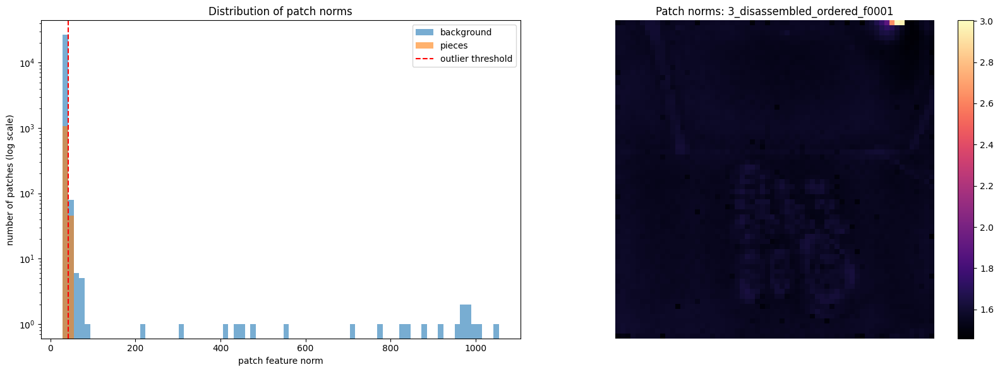

In [25]:
# 6.6 Patch-norm analysis: are there high-norm outlier patches in the background?
all_norms, all_ids, on_border = [], [], []
for ref in REFERENCE_FRAMES:
    norms = np.linalg.norm(ref["features"], axis=-1)                 # (h, w): length of each patch vector
    border = np.zeros_like(norms, dtype=bool)
    b = PCA_BORDER_EXCLUDE
    border[:b, :] = border[-b:, :] = border[:, :b] = border[:, -b:] = True
    all_norms.append(norms.ravel())
    all_ids.append(ref["patch_labels"].ravel())
    on_border.append(border.ravel())
all_norms, all_ids, on_border = map(np.concatenate, (all_norms, all_ids, on_border))

bg_norms = all_norms[all_ids == 0]
piece_norms = all_norms[(all_ids > 0) & (all_ids < IGNORE_ID)]

# Outliers: Tukey's far-out fence (Q3 + 3*IQR), a standard, parameter-free definition
q1, q3 = np.percentile(bg_norms, [25, 75])
outlier_threshold = q3 + 3 * (q3 - q1)
is_bg_outlier = (all_ids == 0) & (all_norms > outlier_threshold)

print(f"Median norm   background: {np.median(bg_norms):.1f}   pieces: {np.median(piece_norms):.1f}")
print(f"Outlier threshold: {outlier_threshold:.1f}")
print(f"Background outliers: {is_bg_outlier.sum()} / {len(bg_norms)} ({is_bg_outlier.sum() / len(bg_norms):.2%})")
if is_bg_outlier.any():
    print(f"  of which on the image border: {on_border[is_bg_outlier].mean():.0%}")
    print(f"  max outlier norm / median background norm: {all_norms[is_bg_outlier].max() / np.median(bg_norms):.1f}x")

# Does this C-RADIO version use register tokens? (registers are the fix proposed by Darcet et al.)
print("Register-related config entries:",
      {k: v for k, v in model.config.to_dict().items() if "reg" in k.lower()} or "none found in config")

# Plots: histogram + norm map of the example frame (same frame as the PCA in 3.6)
example_ref = next(r for r in REFERENCE_FRAMES if r["frame"] == EXAMPLE_FRAME.stem)
example_norms = np.linalg.norm(example_ref["features"], axis=-1)

extreme = (all_ids == 0) & (all_norms > EXTREME_NORM_FACTOR * np.median(bg_norms))
print(f"Share of all patches on the border (expected if random): {on_border.mean():.0%}")
print(f"Extreme outliers (> 5x median): {extreme.sum()}, of which on the border: {on_border[extreme].mean():.0%}")
# Are extreme patches always at the same grid positions? (position-dependent fixed-pattern noise)
extreme_threshold = 5 * np.median(bg_norms)
for ref in REFERENCE_FRAMES:
    rows, cols = np.where(np.linalg.norm(ref["features"], axis=-1) > extreme_threshold)
    print(f"{ref['frame']:<32} {list(zip(rows.tolist(), cols.tolist()))}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bins = np.linspace(all_norms.min(), all_norms.max(), 80)
axes[0].hist(bg_norms, bins=bins, alpha=0.6, label="background", log=True)
axes[0].hist(piece_norms, bins=bins, alpha=0.6, label="pieces", log=True)
axes[0].axvline(outlier_threshold, color="red", linestyle="--", label="outlier threshold")
axes[0].set_xlabel("patch feature norm")
axes[0].set_ylabel("number of patches (log scale)")
axes[0].legend()
axes[0].set_title("Distribution of patch norms")

im = axes[1].imshow(np.log10(example_norms), cmap="magma")
axes[1].set_title(f"Patch norms (log10): {example_ref['frame']}")
axes[1].set_title(f"Patch norms: {example_ref['frame']}")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

Extreme patches in a uniform grey image: [[0, 56], [0, 57], [0, 58]]


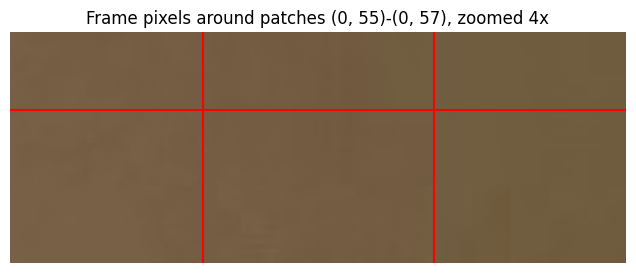

In [26]:
# 6.7 Fixed-pattern test: uniform grey image
# Is the anomaly produced by the model (fixed-pattern noise) or by something in the frames?
# 1. Feed a uniform grey image: it has no content, so any anomaly comes from the model itself.
blank = Image.new("RGB", (1024, 1024), (128, 128, 128))
blank_features, _ = extract_patch_features(blank)
blank_norms = np.linalg.norm(blank_features, axis=-1)
print("Extreme patches in a uniform grey image:",
      np.argwhere(blank_norms > 5 * np.median(blank_norms)).tolist())

# 2. Look at the pixels of that region in a real frame (patches (0, 55)-(0, 57) = x 880-928, y 0-16).
region = example_image.crop((840, 0, 968, 48)).resize((512, 192), Image.Resampling.NEAREST)
plt.figure(figsize=(8, 3))
plt.imshow(region)
plt.axvline((880 - 840) * 4, color="red")
plt.axvline((928 - 840) * 4, color="red")
plt.axhline(16 * 4, color="red")
plt.title("Frame pixels around patches (0, 55)-(0, 57), zoomed 4x")
plt.axis("off")
plt.show()

Observation 6.6 - 6.7: Typical patch norms are similar for background and pieces (median 36.3 vs 38.3). 111 background patches (0.42%) exceed Tukey's far-out fence. 21 of them are extreme (up to 29x the median norm): they are always the same three patches, row 0, columns 55–57, in all 7 reference frames. The frame pixels there are plain wall, and a uniform grey image produces the same anomaly at row 0, columns 56–58: the artifact comes from the model, not from the images. This is the position-dependent fixed-pattern noise inherited from the teachers and described in the C-RADIOv4 tech report (Sec. 2.3, Fig. 2; DVT, Yang et al. 2024), which the training mitigates but does not fully remove at the border of the backbone features. The extreme patches entered the background prototype, but after normalization they weigh like any other patch (6.5). They may cause false positives in classification: handled in Section 9.

6.8 Labelling rule check. Prototypes are rebuilt with the center-pixel rule (5.3), using the same features and pixel maps: only the patch labelling rule changes. If the two versions are much closer to each other than two different classes are, the rule does not affect the prototypes.

In [27]:
# 6.8 Does the labelling rule change the prototypes? Center-pixel rule vs coverage rule
center = PATCH_SIZE // 2

# Same features, same pixel maps: only the patch labelling rule changes.
# Old rule: each patch takes the label of its center pixel (IGNORE_ID and background included).
center_rule_frames = [
    {"features": ref["features"],
     "patch_labels": ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE]}
    for ref in REFERENCE_FRAMES
]
center_prototypes, center_patch_counts = build_prototypes(center_rule_frames)

rule_comparison = pd.DataFrame({
    name: {
        "patches (center pixel)": center_patch_counts[name],
        "patches (coverage >= 0.5)": prototype_patch_counts[name],
        "cosine(center, coverage)": float(center_prototypes[name] @ prototypes[name]),
    }
    for name in prototype_names
}).T
rule_comparison["patches (center pixel)"] = rule_comparison["patches (center pixel)"].astype(int)
rule_comparison["patches (coverage >= 0.5)"] = rule_comparison["patches (coverage >= 0.5)"].astype(int)
display(rule_comparison.round(4))

,patches (center pixel),patches (coverage >= 0.5),"cosine(center, coverage)"
background,27209,26744,0.9999
body,234,226,0.9999
base,186,184,0.9999
hat,37,38,0.9992
eyes,25,24,0.9995
ear,40,39,0.9999
nose,26,23,0.9991
moustache,28,27,0.9996
mouth,21,20,0.9996
arm_1,33,28,0.9987


Observation 6.8: The labelling rule does not affect the prototypes: cosine between center-pixel and coverage prototypes is ≥ 0.998 for all classes. The largest changes are for thin pieces (arm_2 0.9982, arm_1 0.9987, nose 0.9991). These changes are at least 27 times smaller than the distance between each class and its nearest class (8.2). The coverage rule is kept because it is cleaner and justified (5.3).

References Section 6:

Snell et al. 2017, Sez. 2.2: prototype = mean of examples;

Mensink et al. 2013: nearest class mean;

Banerjee et al. 2005, Unit Hypersphere: normalized mean as an estimate of the average direction von Mises-Fisher;

Qi et al. 2018: same procedure as weight imprinting;

Chen et al. 2019: frozen pre-trained features and simple classifier as strong baseline

For known high-norm artifact phenomenon in ViT:
C-RADIOv4 tech report Sez. 2.3
Yang et al. 2024 (DVT)
Darcet et al. 2024



## Section 7 - Support-set gallery

How each class appears in each reference frame. Yellow: the annotated polygon (pixel level). Bright: the 16x16 patches that enter the prototype (patch level). Dimmed: background or ignored mixed patches.

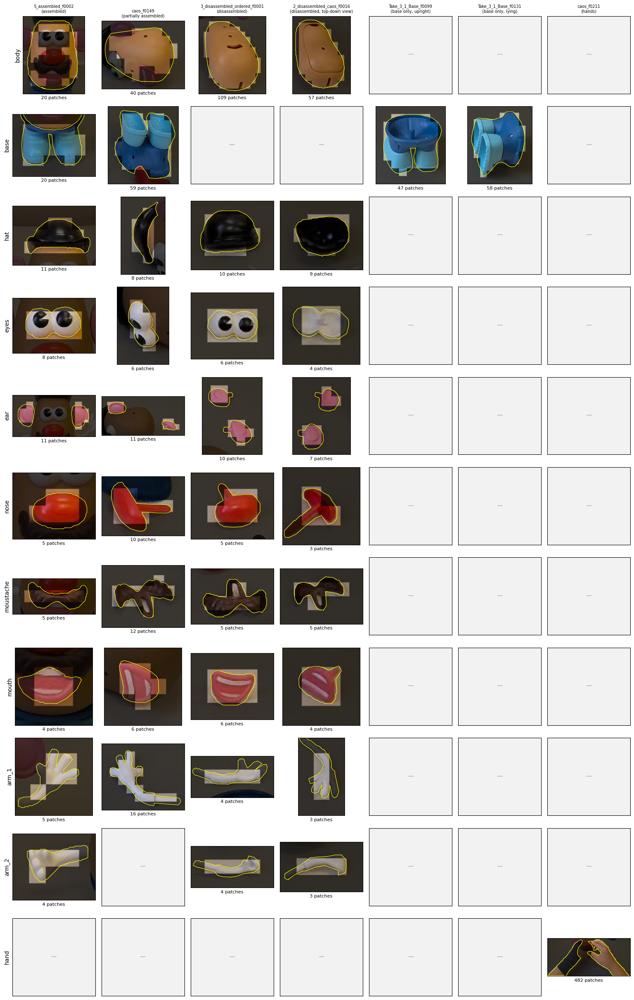

In [28]:
# 7.1 Support-set gallery: how each class appears in each reference frame.
# Rows = classes, columns = reference frames. Each crop shows the piece with the patches
# that enter its prototype at full brightness; everything else is dimmed.
gallery_classes = [name for name in CLASS_NAMES if name != BACKGROUND_LABEL]
resized_images = {
    ref["frame"]: np.asarray(Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"]),
                             dtype=np.float32) / 255
    for ref in REFERENCE_FRAMES
}

fig, axes = plt.subplots(len(gallery_classes), len(REFERENCE_FRAMES),
                         figsize=(2.2 * len(REFERENCE_FRAMES), 2.2 * len(gallery_classes)))

for r, name in enumerate(gallery_classes):
    annotations = {ref["frame"]: json.load(open(ref["json_path"])) for ref in REFERENCE_FRAMES}
    class_id = CLASS_NAMES.index(name)
    for c, ref in enumerate(REFERENCE_FRAMES):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        mask = ref["patch_labels"] == class_id

        if not mask.any():
            # This frame does not provide this class
            ax.set_facecolor("0.95")
            ax.text(0.5, 0.5, "—", ha="center", va="center", color="0.6", transform=ax.transAxes)
        else:
            # Crop: bounding box of the class patches, plus a margin (in patches)
            rows, cols = np.where(mask)
            h_p, w_p = mask.shape
            r0, r1 = max(rows.min() - GALLERY_MARGIN, 0), min(rows.max() + 1 + GALLERY_MARGIN, h_p)
            c0, c1 = max(cols.min() - GALLERY_MARGIN, 0), min(cols.max() + 1 + GALLERY_MARGIN, w_p)

            # Patch mask -> pixel mask; dim every pixel that is not in a prototype patch
            pixel_mask = np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE)))[..., None]
            shown = resized_images[ref["frame"]] * np.where(pixel_mask, 1.0, GALLERY_DIM_FACTOR)
            ax.imshow(shown[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
            ax.set_xlabel(f"{mask.sum()} patches", fontsize=8)
            # Overlay the original polygon outline (pixel-precise annotation) on the patch view
            ann = annotations[ref["frame"]]
            scale_x = ref["resized_size"][0] / ann["imageWidth"]
            scale_y = ref["resized_size"][1] / ann["imageHeight"]
            for shape in ann["shapes"]:
                if shape["label"] != name:
                    continue
                pts = np.array(shape["points"] + [shape["points"][0]])       # close the polygon
                ax.plot(pts[:, 0] * scale_x - c0 * PATCH_SIZE, pts[:, 1] * scale_y - r0 * PATCH_SIZE,
                        color="yellow", linewidth=0.8)
            ax.set_xlim(-0.5, (c1 - c0) * PATCH_SIZE - 0.5)
            ax.set_ylim((r1 - r0) * PATCH_SIZE - 0.5, -0.5)

        if r == 0:
            ax.set_title(f"{ref['frame']}\n({ref['role']})", fontsize=7)
        if c == 0:
            ax.set_ylabel(name, fontsize=10)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "support_set_gallery.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 7.1: Each class appears in different states and viewpoints across the reference frames (stratified support set). In the assembled frame, mounted pieces are separated from the body, which is lit only between them (5.1). Thin pieces (arms, nose seen from above) contribute only their central patches: edges and fingers are mixed patches and are ignored. In the assembled frame the figure is small, so crops are low resolution and each piece covers few patches (6.3). In the assembled frame, arm_1 is represented mainly by its open hand: the thin forearm never covers half a patch.

References Section 7: none (visualization of the support set)

## Section 8 - Prototype similarity

How different the prototypes are from each other. Two classes with very similar prototypes are likely to be confused by the classifier (Section 9).

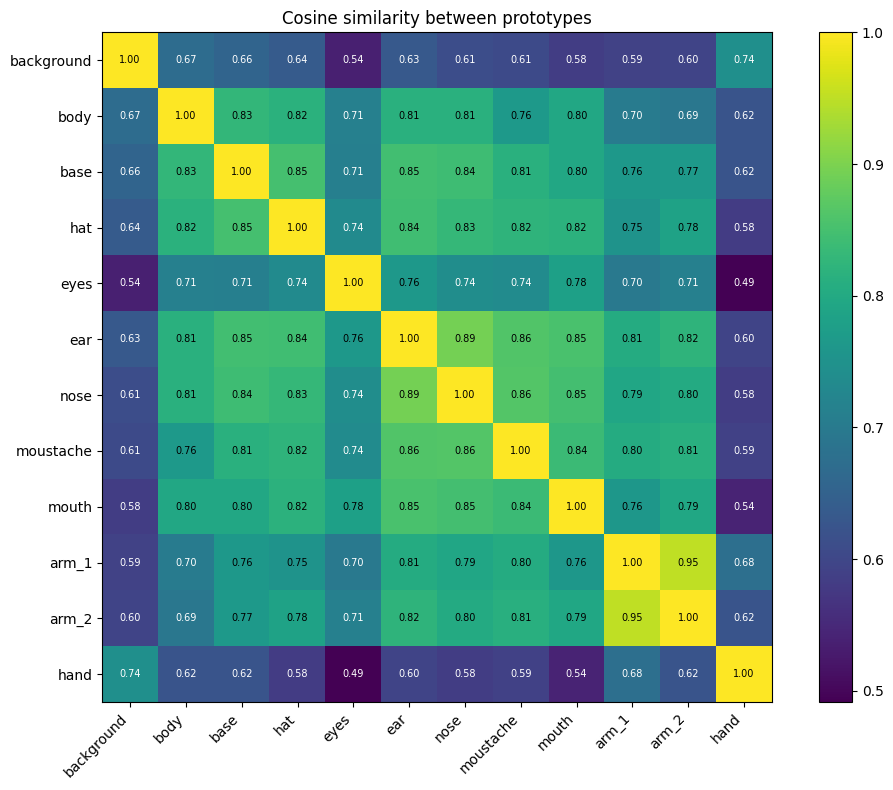

In [29]:
# 8.1 Prototype similarity matrix (cosine similarity between unit prototypes = dot product)
prototype_matrix = np.stack([prototypes[name] for name in prototype_names])
similarity = prototype_matrix @ prototype_matrix.T

off_diagonal = similarity[~np.eye(len(prototype_names), dtype=bool)]
vmin, vmax = off_diagonal.min(), 1.0
midpoint = (vmin + vmax) / 2

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(similarity, cmap="viridis", vmin=vmin, vmax=vmax)
ax.set_xticks(range(len(prototype_names)))
ax.set_xticklabels(prototype_names, rotation=45, ha="right")
ax.set_yticks(range(len(prototype_names)))
ax.set_yticklabels(prototype_names)
for i in range(len(prototype_names)):
    for j in range(len(prototype_names)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="black" if similarity[i, j] > midpoint else "white")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Cosine similarity between prototypes")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "prototype_similarity.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 8.1: The most similar pair is arm_1–arm_2 (0.95): same material and shape, only the hand differs. The small face pieces form a group (ear, nose, moustache, mouth: 0.84–0.89), with nose–ear as the closest pair despite different colors. Eyes are the most distinctive piece (nearest class at 0.78). Body and base are well separated (0.83). The background is far from all pieces (0.54–0.67) except hand (0.74), a harmless confusion since hand is never reported as a piece. All piece prototypes share a high baseline similarity (0.70–0.89): relative differences matter, not absolute values.

In [30]:
# 8.2 For each class: its nearest other class, and how that distance compares
# to the shift caused by the labelling rule (6.8)
nearest_similarity = similarity.copy()
np.fill_diagonal(nearest_similarity, -np.inf)

rows = []
for i, name in enumerate(prototype_names):
    j = int(nearest_similarity[i].argmax())
    distance = 1 - similarity[i, j]
    rule_shift = 1 - rule_comparison.loc[name, "cosine(center, coverage)"]
    rows.append({
        "class": name,
        "nearest class": prototype_names[j],
        "cosine": similarity[i, j],
        "distance (1 - cosine)": distance,
        "rule shift (6.8)": rule_shift,
        "distance / rule shift": distance / rule_shift if rule_shift > 1e-6 else np.inf,
    })

nearest_table = pd.DataFrame(rows).set_index("class").sort_values("cosine", ascending=False)
display(nearest_table.round(4))

,nearest class,cosine,distance (1 - cosine),rule shift (6.8),distance / rule shift
class,,,,,
arm_1,arm_2,0.9504,0.0496,0.0013,38.8025
arm_2,arm_1,0.9504,0.0496,0.0018,27.0870
nose,ear,0.8932,0.1068,0.0009,119.9967
ear,nose,0.8932,0.1068,0.0001,1039.9251
moustache,nose,0.8644,0.1356,0.0004,337.3894
mouth,ear,0.8534,0.1466,0.0004,395.6727
base,hat,0.8504,0.1496,0.0001,2017.2476
hat,base,0.8504,0.1496,0.0008,177.1089
body,base,0.8286,0.1714,0.0001,2402.9574


Observation 8.2: For every class, the distance to its nearest class is at least 27 times larger than the shift caused by the labelling rule (6.8): the rule cannot make two classes swap. The risky pairs for Section 9 are arm_1–arm_2 and the face-piece group. These are confusions between pieces, which the background margin does not address.

References Section 8: no new reference. Distance-based classification with class prototypes (Snell et al. 2017; Mensink et al. 2013, already cited in Section 6) implies that classes with close prototypes are the most likely to be confused: this analysis measures that closeness.

## Section 9 - Classifier 

Nearest-prototype classification with cosine similarity, plus background rejection. One single function, used for test frames (Section 10) and video (Section 11).

9.1 Classifier. Each patch feature is L2-normalized and compared with the 12 prototypes by cosine similarity (a dot product, since prototypes are unit vectors). The patch takes the most similar prototype (nearest class mean, Mensink et al. 2013; Snell et al. 2017). Background rejection: if the winner is not background but its similarity exceeds the background similarity by less than CONFIDENCE_MARGIN (0.03, provisional, studied in a dedicated notebook), the patch is assigned to background. The margin decides only piece vs background, never between two pieces (8.2). Border artifacts (6.6–6.7) are not filtered: Section 10.2 shows they are always classified as background.

In [31]:
# 9.1 Classifier: nearest prototype (cosine similarity) + background rejection margin
assert prototype_names == CLASS_NAMES, "Prototype order must match CLASS_NAMES (colors, indices)"
BACKGROUND_ID = CLASS_NAMES.index(BACKGROUND_LABEL)


def classify_patches(features, prototype_matrix, margin=CONFIDENCE_MARGIN):
    """
    Classify every patch of one frame.

    1. Each patch feature is L2-normalized; its cosine similarity with each prototype is then
       a dot product, since prototypes are unit vectors.
    2. Each patch takes the most similar prototype (nearest class mean).
    3. Background rejection: if the winner is not background, but its similarity exceeds the
       background similarity by less than `margin`, the patch is assigned to background.
       The margin only decides piece vs background, never between two pieces.

    Returns
    -------
    labels : (h, w) class indices into CLASS_NAMES
    similarities : (h, w, K) cosine similarity of each patch with each prototype
    """
    similarities = l2_normalize(features) @ prototype_matrix.T
    labels = similarities.argmax(axis=-1)
    best = similarities.max(axis=-1)
    rejected = (labels != BACKGROUND_ID) & (best - similarities[..., BACKGROUND_ID] < margin)
    labels = np.where(rejected, BACKGROUND_ID, labels)
    return labels, similarities

9.2 Test frames. The 17 test frames (4.3) are classified and their raw similarities saved, so that the margin study can test any margin value without running C-RADIO again.

In [32]:
# 9.2 Classify all test frames and save raw similarities for the margin study
test_results = {}
for test in TEST_FRAMES:
    image = Image.open(test["image_path"]).convert("RGB")
    features, resized_size = extract_patch_features(image)
    labels, similarities = classify_patches(features, prototype_matrix)
    test_results[test["frame"]] = {
        "labels": labels,
        "similarities": similarities,
        "norms": np.linalg.norm(features, axis=-1),   # kept for the border-artifact check (6.6)
        "resized_size": resized_size,
    }

np.savez_compressed(
    OUTPUT_DIR / "test_similarities.npz",
    class_names=np.array(CLASS_NAMES),
    frames=np.array([t["frame"] for t in TEST_FRAMES]),
    **{f"{frame}__similarities": r["similarities"].astype(np.float32) for frame, r in test_results.items()},
    **{f"{frame}__norms": r["norms"].astype(np.float32) for frame, r in test_results.items()},
)

summary = pd.DataFrame({
    t["frame"]: {name: int((test_results[t["frame"]]["labels"] == i).sum()) for i, name in enumerate(CLASS_NAMES)}
    for t in TEST_FRAMES
}).T
display(summary)

,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
assembly_1_f0000,3953,0,2,35,6,33,22,2,0,25,18,0
assembly_1_f0008,3843,12,95,26,23,21,20,19,0,21,16,0
assembly_1_f0016,3823,82,45,28,22,25,15,14,5,21,16,0
assembly_1_f0026,3825,78,41,29,18,27,14,14,12,21,17,0
assembly_1_f0038,3838,64,47,33,23,28,10,9,6,19,19,0
assembly_1_f0054,3862,45,42,32,14,34,8,7,9,26,17,0
assembly_1_f0065,3882,35,44,27,16,27,7,6,11,14,27,0
assembly_1_f0073,3898,25,41,27,15,26,9,6,9,15,25,0
assembly_1_f0020,3523,71,13,27,8,26,18,7,10,24,18,351
assembly_2_f0003,3785,51,77,27,14,14,30,15,1,15,22,45


Observation 9.2: Counts per class, a first coarse check. Base peaks in the base-only frame (95 patches); hand is found when hands are present and absent otherwise. Small pieces get more patches than in the reference frames: Section 10 shows this is not due to false positives on the background (see 10.1).

References Section 9: nearest class mean classification (Mensink et al. 2013; Snell et al. 2017, already cited in Section 6). The background rejection margin is provisional and studied in a dedicated notebook, where its literature is discussed.

## Section 10 - Qualitative evaluation on test frames

Predicted patch labels on the 17 test frames (4.3), from sequences never used for prototypes. Qualitative only: quantitative evaluation requires annotated test frames and is done in the margin study.

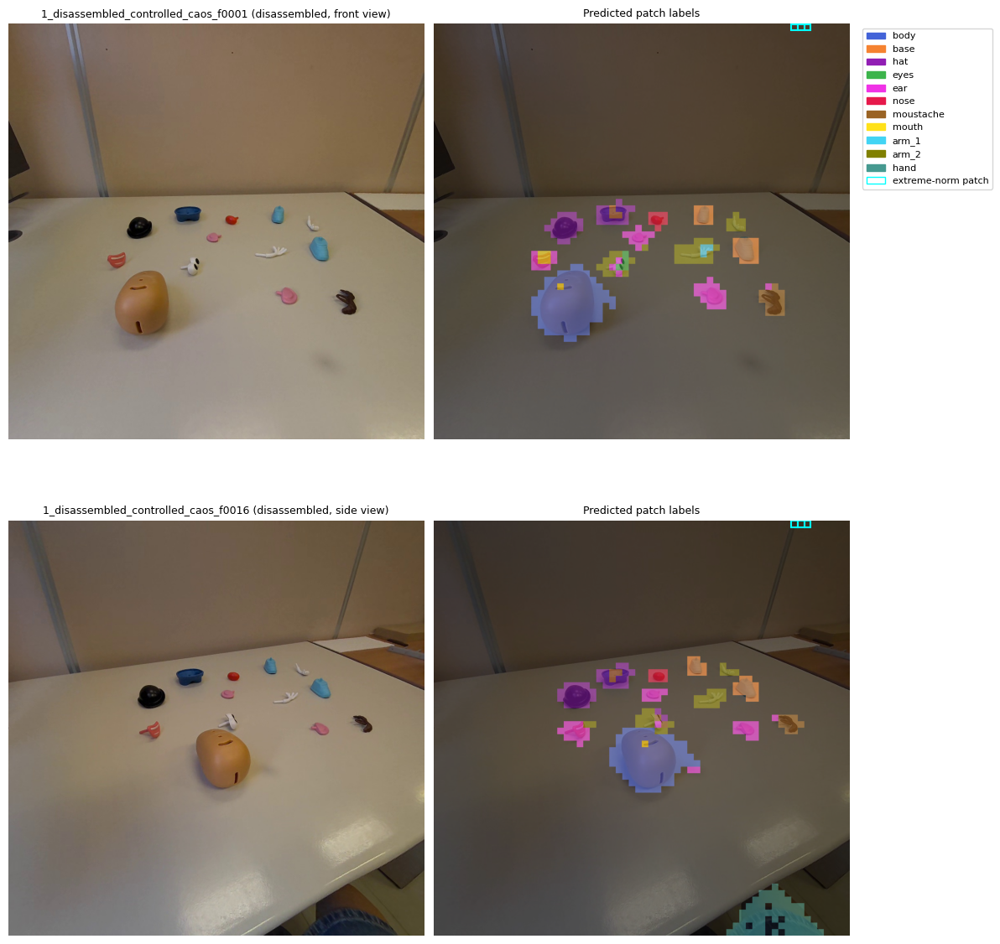

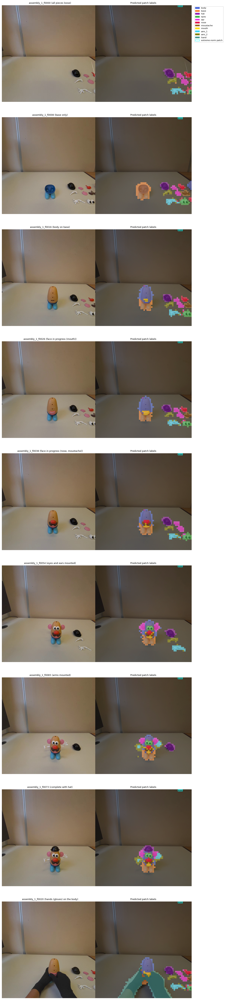

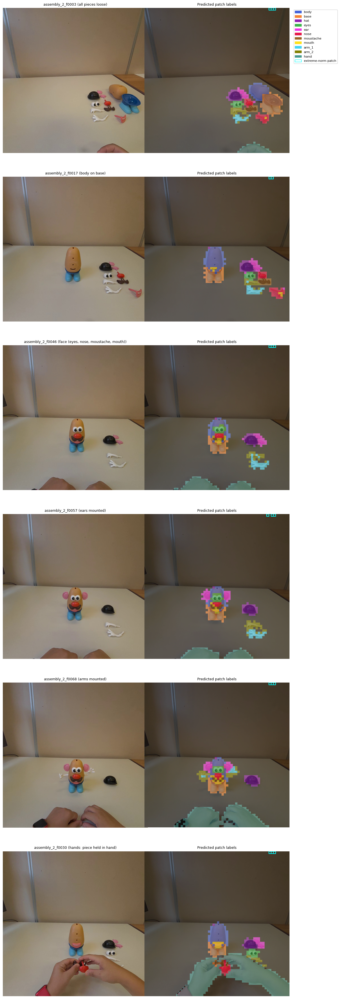

In [33]:
# 10.1 Predicted patch labels on the test frames, one figure per test sequence.
# Left: test frame. Right: predicted pieces in color over the dimmed frame; background not colored.
# Cyan squares: extreme-norm patches (border artifacts, 6.6-6.7).
legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES if n != BACKGROUND_LABEL] + \
         [mpatches.Patch(facecolor="none", edgecolor="cyan", label="extreme-norm patch")]

for sequence in sorted(TEST_SEQUENCES):
    tests = [t for t in TEST_FRAMES if t["sequence"] == sequence]
    fig, axes = plt.subplots(len(tests), 2, figsize=(12, 6 * len(tests)), squeeze=False)
    for (ax_image, ax_pred), test in zip(axes, tests):
        result = test_results[test["frame"]]
        size = result["resized_size"]
        image = np.asarray(Image.open(test["image_path"]).convert("RGB").resize(size), dtype=np.float32) / 255
        color = cv2.resize(label_grid_to_rgb(result["labels"]).astype(np.float32), size, interpolation=cv2.INTER_NEAREST)
        is_piece = cv2.resize((result["labels"] != BACKGROUND_ID).astype(np.uint8), size,
                              interpolation=cv2.INTER_NEAREST)[..., None].astype(bool)
        overlay = np.where(is_piece, 0.45 * image + 0.55 * color, 0.6 * image)

        ax_image.imshow(image)
        ax_image.set_title(f"{test['frame']} ({test['stage']})", fontsize=9)
        ax_pred.imshow(overlay)
        ax_pred.set_title("Predicted patch labels", fontsize=9)

        extreme = np.argwhere(result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"]))
        for r, c in extreme:
            ax_pred.add_patch(mpatches.Rectangle((c * PATCH_SIZE, r * PATCH_SIZE), PATCH_SIZE, PATCH_SIZE,
                                                 fill=False, edgecolor="cyan", linewidth=1.5))
        for ax in (ax_image, ax_pred):
            ax.axis("off")

    axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"test_predictions_{sequence}.png", dpi=150, bbox_inches="tight")
    plt.show()

Observation 10.1: No false positives on wall or table in any test frame: with margin 0.03 the background is rejected well. Predicted pieces are slightly larger than the real ones: mixed boundary patches, ignored when building prototypes, are assigned to the piece at inference. The assembly is followed at every stage in both videos (gloves and bare hands), and a piece held in hand keeps its class. Errors: loose arms are mixed between arm_1 and arm_2, mostly arm_2 in the disassembled sequence; a mouth lying on its side is predicted as nose (assembly_2_f0003, f0017); eyes are missed in the side view; jeans are predicted as hand (harmless, never reported as a piece). Separated pants and shoes are split between hat and base, as they fall outside the base definition. The choice of reference frames needs further study (support-set study)

In [34]:
# 10.2 Are extreme-norm patches classified as pieces? (border artifacts, 6.6-6.7)
rows = []
for test in TEST_FRAMES:
    result = test_results[test["frame"]]
    extreme = result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"])
    predicted = [CLASS_NAMES[i] for i in result["labels"][extreme]]
    rows.append({
        "frame": test["frame"],
        "extreme patches": int(extreme.sum()),
        "positions": np.argwhere(extreme).tolist(),
        "predicted as": ", ".join(predicted) or "-",
    })
display(pd.DataFrame(rows).set_index("frame"))

,extreme patches,positions,predicted as
frame,,,
assembly_1_f0000,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0008,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0016,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0026,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0038,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0054,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0065,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0073,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_1_f0020,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"


Observation 10.2: The extreme-norm border patches (6.6–6.7) are classified as background in all 17 test frames: they cause no false positives, so no filtering is needed. Their positions shift slightly in two frames (column 54; only 2 patches), consistent with a small content-dependent component of the fixed-pattern noise.

References Section 10: no new reference. Test frames come from sequences never used for prototypes (split by recording, Section 4.3: Sener et al. 2022; Schoonbeek et al. 2024). This evaluation is qualitative; the quantitative evaluation (per-class IoU on annotated test frames, with ignored boundary patches excluded as in PASCAL VOC and Cityscapes, Section 5) is done in the margin and support-set studies.